# Tarea 1 – Analítica de Datos (MACI 2026)

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

**Data Wrangling**

**Entrada:** `data/output/data_raw.csv` (última extracción del notebook 01) → **Salida:** `data/processed/data_processed.csv`

| Paso | Qué hace |
|---|---|
| 1 | Librerías y rutas |
| 2 | Diagnóstico de calidad del RAW: faltantes y duplicados, por columna y por fila |
| 3 | Limpieza: texto → números, filas sin precio y duplicados fuera |
| 4 | Imputación de faltantes y guardado |


Las cifras de las interpretaciones corresponden a la extracción del **03-11-2026** (columna `fecha_extraccion`). Si vuelves a ejecutar el scraping, revisa los números antes de entregar.

### Paso 1 · Librerías y rutas

In [1]:
# Librerías que usa este notebook

import numpy as np                 # cálculos numéricos (np.where para descontar cupones)
import pandas as pd                # tablas: leer, limpiar y guardar CSV
from pathlib import Path           # rutas de carpetas (OUT y PROC)

In [2]:
# Carpeta de salida: busca "data/output" subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz del proyecto)

OUT = next((p / "data" / "output" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "output").is_dir()), Path("data/output"))
OUT.mkdir(parents=True, exist_ok=True)                # si no existe, la crea
PROC = OUT.parent / "processed"                       # data/processed: misma ruta, carpeta hermana de output
PROC.mkdir(exist_ok=True)                             # si no existe, la crea
print("RAW →", OUT.resolve(), "\nProcesados →", PROC.resolve())

RAW → /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/output 
Procesados → /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed


### Paso 2 · Diagnóstico de calidad del RAW (antes de limpiar)

Se cuentan los faltantes por columna y por fila, y los duplicados. Hay **tres tipos de faltante**, y cada uno se trata distinto:
1. **Estructural** (`cupon_tipo`, `cupon_monto`): vacío significa "la tienda no tiene cupón". No es un dato perdido: se toma como descuento 0.
2. **Sin precio liberado** (`tienda`, precios y `condicion` vacíos): el modelo solo se vende con plan. Se elimina la fila.
3. **No informado** ("N/A" en peso, batería, cámara frontal…): el sitio no publica el dato. Se imputa con la mediana de la marca.

#### 2.1 Faltantes y repetidos por columna

1017 filas × 32 columnas = 32544 celdas | faltantes: 2044 (6.3%)


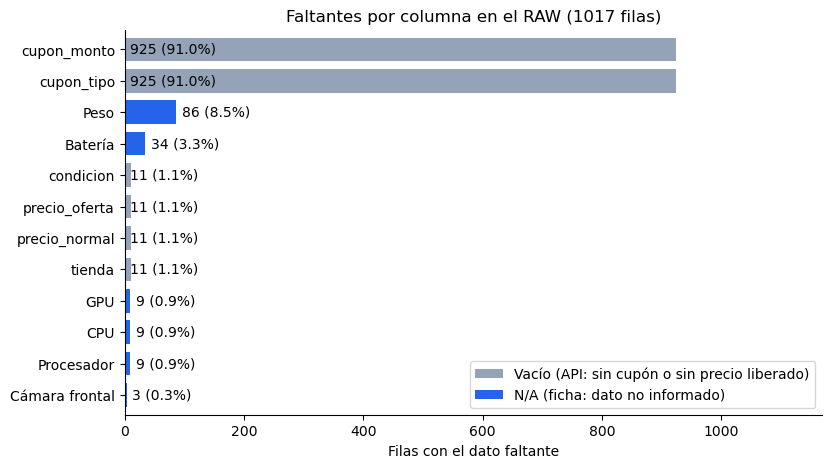

,vacíos,N/A,NaN total,% NaN,únicos,repetidos
nombre,0,0,0,0.0,251,766
marca,0,0,0,0.0,16,1001
id,0,0,0,0.0,251,766
Pantalla,0,0,0,0.0,137,880
Memoria interna,0,0,0,0.0,7,1010
RAM,0,0,0,0.0,8,1009
Cámara principal,0,0,0,0.0,96,921
Cámara frontal,0,3,3,0.3,24,990
Batería,0,34,34,3.3,77,906
Sistema operativo,0,0,0,0.0,22,995


In [3]:
# Diagnóstico de calidad del RAW, antes de limpiar

import matplotlib.pyplot as plt                                            # gráficos (súbelo también a la celda de librerías)

df  = pd.read_csv(OUT / "data_raw.csv")                                    # como lo ve pandas: "" y "N/A" pasan a NaN
txt = pd.read_csv(OUT / "data_raw.csv", dtype=str, keep_default_na=False)  # como texto puro: deja ver "" y "N/A" por separado

calidad = pd.DataFrame({
    "vacíos":    txt.eq("").sum(),                 # celda sin nada (ej. tienda sin cupón, modelo sin precio liberado)
    "N/A":       txt.eq("N/A").sum(),              # el sitio publica "N/A": dato no informado
    "NaN total": df.isna().sum(),                  # lo que pandas trata como faltante (= vacíos + N/A)
    "% NaN":     (df.isna().mean() * 100).round(1),
    "únicos":    df.nunique(),                     # valores distintos en la columna
    "repetidos": df.count() - df.nunique(),        # valores no vacíos que ya habían aparecido en la columna
})
print(f"{df.shape[0]} filas × {df.shape[1]} columnas = {df.size} celdas | faltantes: {df.isna().sum().sum()} ({df.isna().sum().sum() / df.size:.1%})")

# Gráfico: faltantes por columna, separando vacíos (gris) y "N/A" (azul)
g = calidad[calidad["NaN total"] > 0].sort_values("NaN total")            # solo columnas con faltantes, de menor a mayor
ax = g[["vacíos", "N/A"]].plot.barh(stacked=True, color=["#94a3b8", "#2563eb"], figsize=(9, 5), width=0.75)   # barras apiladas
ax.bar_label(ax.containers[-1], labels=[f"{n} ({p}%)" for n, p in zip(g["NaN total"], g["% NaN"])], padding=4)  # total y % al final
ax.set_xlim(right=len(df) * 1.15)                                         # eje hasta el total de filas, con espacio para etiquetas
ax.set(title=f"Faltantes por columna en el RAW ({len(df)} filas)", xlabel="Filas con el dato faltante", ylabel="")
ax.legend(["Vacío (API: sin cupón o sin precio liberado)", "N/A (ficha: dato no informado)"], loc="lower right")
ax.spines[["top", "right"]].set_visible(False)                            # quita bordes que no aportan
plt.show()

calidad                                                                   # la tabla se muestra debajo del gráfico

**Interpretación.**
- El RAW tiene **1.017 filas × 32 columnas = 32.544 celdas**, con **2.044 faltantes (6,3 %)**.

- **El 91 % de los faltantes (1.850 celdas) es estructural:** son los cupones vacíos de las 925 filas (91 %) cuya tienda no ofrece cupón. No falta información.

- **44 celdas (11 filas × 4 columnas)** corresponden a modelos **sin precio liberado** (`tienda`, `precio_normal`, `precio_oferta`, `condicion` vacíos a la vez). Se eliminan en el Paso 3.

- **150 celdas dicen "N/A"** porque el sitio no informa el dato: peso 86 (8,5 %), batería 34 (3,3 %), procesador, CPU y GPU 9 cada una (0,9 %) y cámara frontal 3 (0,3 %). De estas, solo peso, batería y cámara frontal están entre las columnas a limpiar; se imputan en el Paso 4.

- Los **vacíos** y los **"N/A"** nunca coinciden en una misma columna: los vacíos vienen de la API (precios y cupones) y los "N/A", de la ficha HTML (características). Son dos orígenes distintos.

- Los **repetidos por columna son esperables**: hay 251 modelos en 1.017 filas, o sea, cada celular aparece en ~4 tiendas y sus características se repiten. `Bluetooth` y `fecha_extraccion` tienen un solo valor: todos los equipos tienen Bluetooth y todo viene de una sola extracción.

#### 2.2 Faltantes por fila y duplicados

Filas completas: 79 | con al menos 1 faltante: 938
Filas duplicadas exactas: 26 | mismo celular en la misma tienda: 63


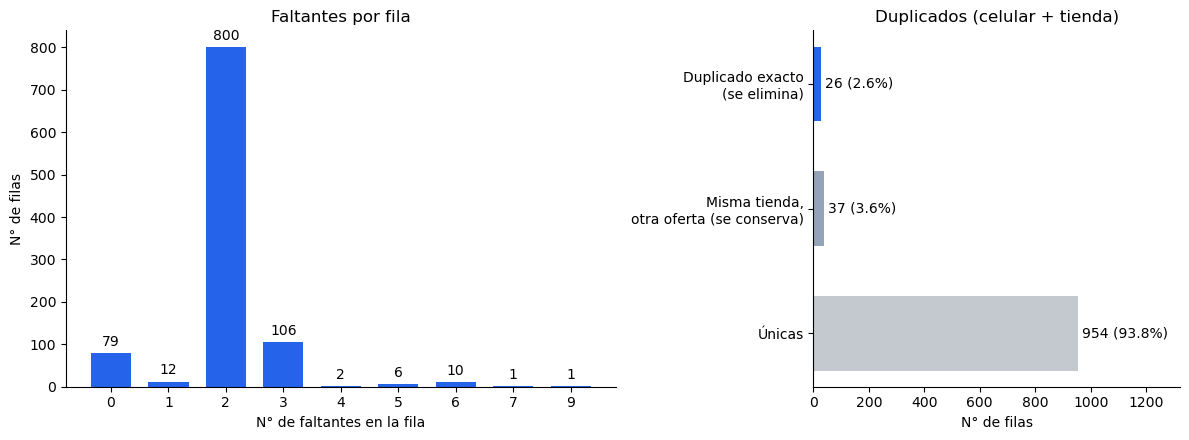

,n° de filas
faltantes en la fila,
0,79
1,12
2,800
3,106
4,2
5,6
6,10
7,1
9,1


In [4]:
por_fila = df.isna().sum(axis=1)                                          # n° de faltantes en cada fila
exactos = df.duplicated().sum()                                           # filas idénticas en TODAS las columnas
clave = df.duplicated(["nombre", "tienda"]).sum()                         # mismo celular en la misma tienda (incluye los exactos)
print(f"Filas completas: {(por_fila == 0).sum()} | con al menos 1 faltante: {(por_fila > 0).sum()}")
print(f"Filas duplicadas exactas: {exactos} | mismo celular en la misma tienda: {clave}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [3, 2]})   # 2 gráficos lado a lado

# Gráfico 1: cuántas filas tienen 0, 1, 2… faltantes
dist = por_fila.value_counts().sort_index()                               # n° de filas por cantidad de faltantes
a1.bar(dist.index.astype(str), dist, color="#2563eb", width=0.7)
a1.bar_label(a1.containers[0], padding=3)                                 # cantidad sobre cada barra
a1.set(title="Faltantes por fila", xlabel="N° de faltantes en la fila", ylabel="N° de filas")

# Gráfico 2: filas únicas vs. duplicadas
dup = pd.Series({"Únicas": len(df) - clave,
                 "Misma tienda,\notra oferta (se conserva)": clave - exactos,   # mismo celular y tienda, distinto precio o condición
                 "Duplicado exacto\n(se elimina)": exactos})
a2.barh(dup.index, dup, color=["#c4c8cf", "#94a3b8", "#2563eb"], height=0.6)
a2.bar_label(a2.containers[0], labels=[f"{v} ({v/len(df):.1%})" for v in dup], padding=3)   # cantidad y % del total
a2.set_xlim(right=len(df) * 1.3)                                          # espacio para las etiquetas
a2.set(title="Duplicados (celular + tienda)", xlabel="N° de filas")

for a in (a1, a2): a.spines[["top", "right"]].set_visible(False)          # quita bordes que no aportan
plt.tight_layout()                                                        # evita que los textos se encimen
plt.show()

dist.rename_axis("faltantes en la fila").to_frame("n° de filas")          # la tabla se muestra debajo del gráfico

**Interpretación.**
- Solo **79 filas (7,8 %) están completas**, pero esa cifra exagera el problema: **800 filas tienen exactamente 2 faltantes**, que son las dos columnas de cupón (estructurales).

- Las filas con **6 o más faltantes** corresponden principalmente a los 11 modelos sin precio liberado, que tienen 6 columnas vacías de una vez (tienda, 2 precios, condición y 2 de cupón).

- **26 filas (2,6 %) son duplicados exactos:** la misma oferta repetida. Se eliminan.

- **63 filas repiten celular + tienda:** 26 son esos duplicados exactos y 37 son ofertas distintas (otro precio o condición: vendedores de marketplace, unidades usadas en distinto estado). Esas 37 se conservan.

#### 2.3 Ejemplos de duplicados exactos

In [5]:
# Ejemplos de filas duplicadas exactas (keep=False muestra todas las copias, no solo las repetidas)
df[df.duplicated(keep=False)].sort_values(["nombre", "tienda"])[["nombre", "tienda", "precio_normal", "precio_oferta", "condicion"]].head(10)

,nombre,tienda,precio_normal,precio_oferta,condicion
121,Apple iPhone 16e (128 GB / White) [MD1R4BE/A],ABC,699990.0,499990.0,https://schema.org/NewCondition
122,Apple iPhone 16e (128 GB / White) [MD1R4BE/A],ABC,699990.0,499990.0,https://schema.org/NewCondition
310,Honor 600 (512 GB / 8 GB / Orange) [5109CHBW-B],Falabella,699990.0,669990.0,https://schema.org/NewCondition
311,Honor 600 (512 GB / 8 GB / Orange) [5109CHBW-B],Falabella,699990.0,669990.0,https://schema.org/NewCondition
297,Honor 600 (512 GB / 8 GB / Orange) [5109CHBW-B],Ripley,619990.0,619990.0,https://schema.org/NewCondition
298,Honor 600 (512 GB / 8 GB / Orange) [5109CHBW-B],Ripley,619990.0,619990.0,https://schema.org/NewCondition
303,Honor 600 (512 GB / 8 GB / Orange) [5109CHBW-B],Tecnomas.cl,650990.0,634990.0,https://schema.org/NewCondition
304,Honor 600 (512 GB / 8 GB / Orange) [5109CHBW-B],Tecnomas.cl,650990.0,634990.0,https://schema.org/NewCondition
552,Honor 600 Elite (256 GB / 8 GB / Desert Gold),CTMAN,470608.0,443970.0,https://schema.org/NewCondition
553,Honor 600 Elite (256 GB / 8 GB / Desert Gold),CTMAN,470608.0,443970.0,https://schema.org/NewCondition


**Interpretación.** Las copias coinciden en todo (celular, tienda, precio y condición): la tienda publica el mismo equipo dos veces, por ejemplo con dos códigos de producto (el Honor 600 en Falabella, Ripley y Tecnomas.cl). Como el RAW no trae ninguna columna que las distinga, contarlas dos veces duplicaría su peso en los promedios por marca y tienda.

### Paso 3 · Limpieza: texto → números

| Columna | Regla de limpieza |
|---|---|
| Precio normal | Precio "normal" o "con todo medio de pago" (ya numérico en la fuente). |
| Precio oferta | Precio tarjeta; si hay cupón se descuenta (% o monto fijo), igual que en la ficha. |
| Memoria / RAM (GB) | Número × unidad: MB ÷ 1024, TB × 1024. |
| Pantalla (pulgadas) | Número pegado a `"`; acepta coma decimal (`8,1"` → 8.1). |
| Cámara principal / frontal (MP) | Suma de todos los números seguidos de "MP" (ignora el "3D" del sensor TOF; corrige "200,0" → 200.0). |
| Batería (mAh), Peso (g) | Primer número del texto. |
| NFC | Sí = 1, No = 0. |
| Reacondicionado | 1 si la condición no es "nuevo" (reacondicionado o usado). |

Además se eliminan las filas sin precio liberado y los duplicados exactos (Paso 2).

Filas duplicadas eliminadas: 26
NaN antes de imputar: {'camara_frontal_mp': 3, 'bateria_mah': 33, 'peso_g': 77}


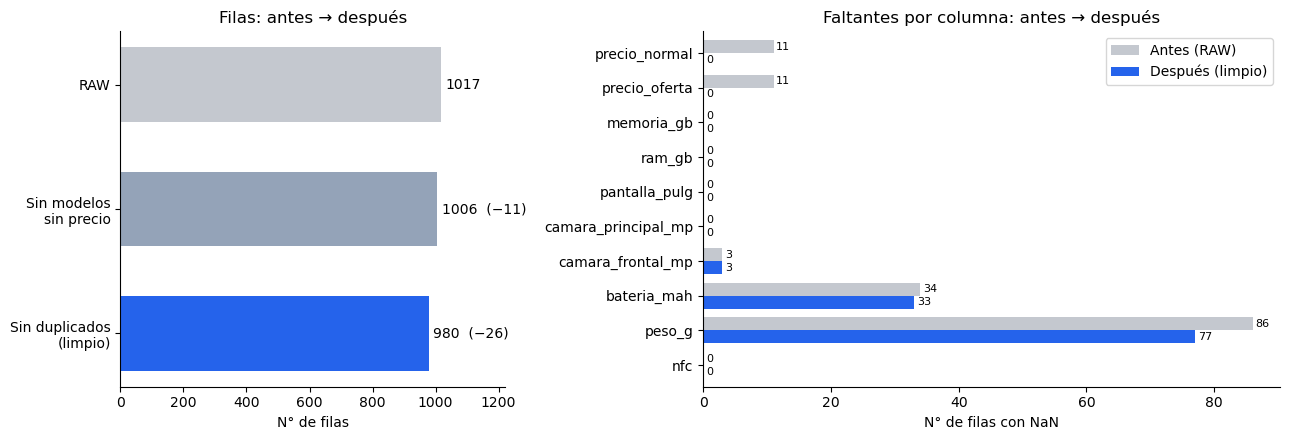

,"antes (RAW, texto)","después (limpio, número)"
Xiaomi 15 Ultra (Black),,
precio_normal,1199990.0,1199990.0
precio_oferta,1199990.0,1154990.0
memoria_gb,512 GB,512.0
ram_gb,16 GB,16.0
pantalla_pulg,"AMOLED 6.7"" táctil (3200x1440) / 120 Hz",6.7
camara_principal_mp,Estándar 50.0 MP + Teleobjetivo Periscopio (Zo...,350.0
camara_frontal_mp,Estándar 32.0 MP,32.0
bateria_mah,5410 mAh,5410.0
peso_g,226 g.,226.0


In [5]:
df = pd.read_csv(OUT / "data_raw.csv")                # vuelve a leer el RAW tal cual (el diagnóstico no lo modifica)

# Herramientas de limpieza (cada una devuelve una columna numérica; si el texto es "N/A" queda NaN)
num = lambda col, patron=r"([\d.]+)": pd.to_numeric(df[col].str.replace(",", ".").str.extract(patron, expand=False), errors="coerce")  # 1er número del texto ("8,1" → 8.1)
gb  = lambda col: num(col) * df[col].str.extract(r"(MB|GB|TB)", expand=False).map({"MB": 1/1024, "GB": 1, "TB": 1024})  # todo a GB
mp  = lambda col: df[col].str.replace(",", ".").str.extractall(r"([\d.]+) MP")[0].astype(float).groupby(level=0).sum()  # suma de "X MP"

# Precio oferta = precio tarjeta; si la tienda tiene cupón, se le descuenta (así lo muestra la ficha: "$239.990 → $227.991")
desc = np.where(df.cupon_tipo.eq("Percentage"), df.precio_oferta * df.cupon_monto / 100, df.cupon_monto.fillna(0))

clean = pd.DataFrame({
    "nombre": df.nombre,                                                   # identificador único
    "marca": df.marca.str.strip(),
    "tienda": df.tienda,
    "reacondicionado": (df.condicion != "https://schema.org/NewCondition").astype(int),   # 1 = reacondicionado o usado
    "precio_normal": df.precio_normal,
    "precio_oferta": (df.precio_oferta - desc).round(),
    "memoria_gb": gb("Memoria interna"),          # "1 TB" → 1024
    "ram_gb": gb("RAM"),                           # "128 MB" → 0.125
    "pantalla_pulg": num("Pantalla", r'([\d.]+)"'),   # el número pegado a las comillas: '... 6.1" táctil' → 6.1
    "camara_principal_mp": mp("Cámara principal"),    # "Estándar 48.0 MP + Gran angular 12.0 MP" → 60.0
    "camara_frontal_mp": mp("Cámara frontal"),
    "bateria_mah": num("Batería"),
    "peso_g": num("Peso"),                         # "218 g." → 218
    "nfc": df.NFC.map({"Sí": 1, "No": 0}),          # 1 = Sí, 0 = No
}).dropna(subset=["precio_oferta"])               # fuera los modelos sin precio de equipo liberado (solo se venden con plan)

n_con_precio = len(clean)                         # filas que quedan tras quitar los modelos sin precio (para el gráfico)
print("Filas duplicadas eliminadas:", clean.duplicated().sum())
clean = clean.drop_duplicates()                   # fila idéntica = la misma oferta repetida: no aporta información y duplica su peso
print("NaN antes de imputar:", clean.isna().sum()[lambda x: x > 0].to_dict())

# ---------- Antes vs. después ----------
origen = {"precio_normal": "precio_normal", "precio_oferta": "precio_oferta", "memoria_gb": "Memoria interna",
          "ram_gb": "RAM", "pantalla_pulg": "Pantalla", "camara_principal_mp": "Cámara principal",
          "camara_frontal_mp": "Cámara frontal", "bateria_mah": "Batería", "peso_g": "Peso", "nfc": "NFC"}   # columna limpia → columna RAW

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 3]})

# Gráfico 1: filas en cada etapa
etapas = pd.Series({"RAW": len(df), "Sin modelos\nsin precio": n_con_precio, "Sin duplicados\n(limpio)": len(clean)})
a1.barh(etapas.index[::-1], etapas[::-1], color=["#2563eb", "#94a3b8", "#c4c8cf"], height=0.6)   # de arriba (RAW) hacia abajo
quitadas = -etapas.diff().fillna(0).astype(int)                       # filas eliminadas en cada etapa
a1.bar_label(a1.containers[0], labels=[f"{v}" + (f"  (−{q})" if q else "") for v, q in zip(etapas[::-1], quitadas[::-1])], padding=3)
a1.set_xlim(right=len(df) * 1.2); a1.set(title="Filas: antes → después", xlabel="N° de filas")

# Gráfico 2: faltantes por columna, en el RAW vs. en la tabla limpia (lo que queda por imputar)
nan = pd.DataFrame({"Antes (RAW)": df[list(origen.values())].isna().sum().values,
                    "Después (limpio)": clean[list(origen)].isna().sum().values}, index=list(origen))
nan.plot.barh(ax=a2, color=["#c4c8cf", "#2563eb"], width=0.75)
for c in a2.containers: a2.bar_label(c, padding=2, fontsize=8)          # número al final de cada barra
a2.invert_yaxis(); a2.set(title="Faltantes por columna: antes → después", xlabel="N° de filas con NaN", ylabel="")

for a in (a1, a2): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# Ejemplo de transformación en una fila: texto del RAW → número limpio
i = clean.camara_principal_mp.idxmax()            # el equipo con más megapíxeles (muestra bien la suma de cámaras)
pd.DataFrame({"antes (RAW, texto)": df.loc[i, list(origen.values())].values,
              "después (limpio, número)": clean.loc[i, list(origen)].values}, index=list(origen)).rename_axis(df.nombre[i])

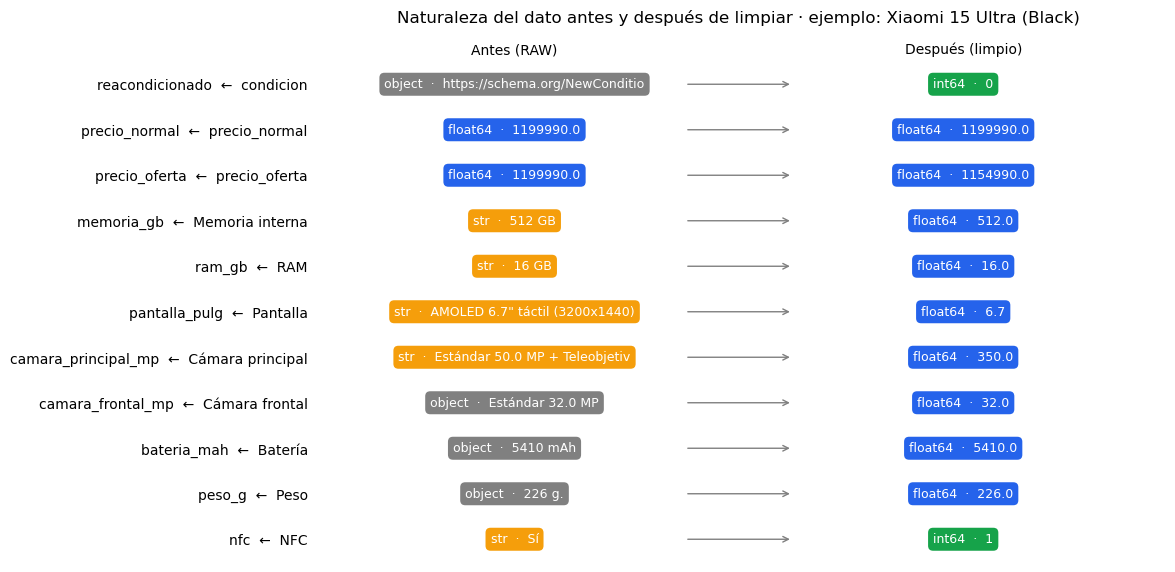

,antes,después
reacondicionado,object,int64
precio_normal,float64,float64
precio_oferta,float64,float64
memoria_gb,str,float64
ram_gb,str,float64
pantalla_pulg,str,float64
camara_principal_mp,str,float64
camara_frontal_mp,object,float64
bateria_mah,object,float64
peso_g,object,float64


In [6]:
# Naturaleza del dato: tipo de cada columna antes (RAW) y después (limpio), con un valor de ejemplo
cols = {"reacondicionado": "condicion", **origen}                       # columna limpia → columna RAW (suma "condicion")
i = clean.camara_principal_mp.idxmax()                                  # mismo equipo de ejemplo que la tabla anterior
tipo = lambda s: "str" if pd.api.types.is_string_dtype(s) else str(s.dtype)   # nombre simple del tipo de la columna
color = {"str": "#f59e0b", "float64": "#2563eb", "int64": "#16a34a"}    # naranja = texto, azul = decimal, verde = entero

fig, ax = plt.subplots(figsize=(11, 6.5))
for y, (limpia, cruda) in enumerate(cols.items()):                     # una fila del gráfico por columna
    for x, s, v in [(0, df[cruda], df.loc[i, cruda]), (1, clean[limpia], clean.loc[i, limpia])]:   # x=0 antes, x=1 después
        t = tipo(s)
        ax.text(x, y, f"{t}  ·  {str(v)[:30]}", ha="center", va="center", fontsize=9, color="white",
                bbox=dict(boxstyle="round,pad=0.4", facecolor=color.get(t, "gray"), edgecolor="none"))
    ax.annotate("", xy=(0.62, y), xytext=(0.38, y), arrowprops=dict(arrowstyle="->", color="gray"))   # flecha antes → después

ax.set_yticks(range(len(cols)), [f"{c}  ←  {r}" for c, r in cols.items()])   # columna limpia ← columna RAW
ax.set_xticks([0, 1], ["Antes (RAW)", "Después (limpio)"]); ax.xaxis.tick_top()
ax.set(xlim=(-0.45, 1.45), ylim=(len(cols) - 0.5, -0.5))
ax.set_title(f"Naturaleza del dato antes y después de limpiar · ejemplo: {df.nombre[i]}", pad=28)
for lado in ax.spines.values(): lado.set_visible(False)                 # sin marco
ax.tick_params(length=0)
plt.show()

pd.DataFrame({"antes": [tipo(df[r]) for r in cols.values()], "después": [tipo(clean[c]) for c in cols]}, index=list(cols))   # resumen en tabla

### Paso 4 · Imputación de faltantes y guardado

**Justificación:**
- **Cupones vacíos:** descuento 0 (Paso 3). La tienda no tiene cupón; no es un dato perdido.

- **Modelos sin precio liberado:** eliminados (Paso 3). Sin precio no sirven ni para el análisis ni como etiqueta del modelo.

- **Duplicados exactos:** eliminados (Paso 3). La misma oferta repetida no aporta información y duplica su peso.

- **Características en "N/A"** (peso, batería, cámara frontal): se imputan con la **mediana de su marca**, porque los equipos de una marca comparten componentes. Si toda la marca es N/A (por ejemplo, Apple no publica la batería), se usa la mediana general. Se usa la mediana y no el promedio porque es robusta a valores extremos (plegables, equipos básicos), y se calcula sobre modelos únicos para que un celular vendido en muchas tiendas no pese más.

(980, 14) | NaN restantes: 0 | duplicados: 0


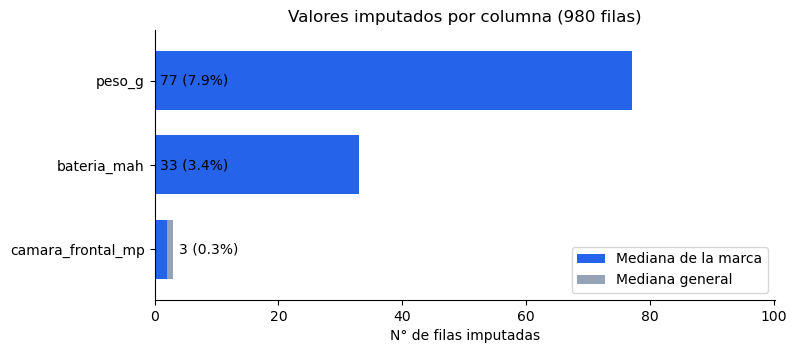

,Mediana de la marca,Mediana general
camara_frontal_mp,2,1
bateria_mah,33,0
peso_g,77,0


In [7]:
# Imputación: NaN → mediana de su marca; si la marca no tiene ningún valor para esa columna → mediana general.

specs = clean.columns[6:]                                      # columnas técnicas
u = clean.drop_duplicates("nombre")                            # 1 fila por modelo: un celular en 10 tiendas no pesa 10 veces
med_marca = clean[["marca"]].join(u.groupby("marca")[specs].median(), on="marca")   # mediana de la marca, repetida en cada fila

antes = clean[specs].isna()                                    # dónde había NaN antes de imputar (True = faltante)
paso1 = clean[specs].fillna(med_marca[specs])                  # 1° intento: mediana de la marca
imp = pd.DataFrame({"Mediana de la marca": antes.sum() - paso1.isna().sum(),   # NaN que se llenaron en el 1° intento
                    "Mediana general": paso1.isna().sum()})                    # NaN que siguieron vacíos → 2° intento
clean[specs] = paso1.fillna(u[specs].median())                 # 2° intento: mediana de todos los modelos

clean.to_csv(PROC / "data_processed.csv", index=False)         # se guarda en data/processed
print(clean.shape, "| NaN restantes:", clean.isna().sum().sum(), "| duplicados:", clean.duplicated().sum())

# Gráfico: cuántos valores se imputaron por columna y con qué método
g = imp[imp.sum(axis=1) > 0].sort_values("Mediana de la marca")              # solo columnas con imputaciones
ax = g.plot.barh(stacked=True, color=["#2563eb", "#94a3b8"], figsize=(8, 3.5), width=0.7)
ax.bar_label(ax.containers[-1], labels=[f"{n} ({n/len(clean):.1%})" for n in g.sum(axis=1)], padding=4)   # total y % de filas
ax.set_xlim(right=g.sum(axis=1).max() * 1.3)                   # espacio para las etiquetas
ax.set(title=f"Valores imputados por columna ({len(clean)} filas)", xlabel="N° de filas imputadas", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

imp[imp.sum(axis=1) > 0]                                       # la tabla se muestra debajo del gráfico

**Control final:** el archivo guardado debe tener **0 NaN y 0 duplicados**. Con la extracción del 03-11: 1.017 filas del RAW − 11 sin precio liberado − 26 duplicados = **980 filas × 14 columnas**.